# 01 – Exploratory Data Analysis: Music Hits

**Goal of the competition:** predict the probability that a song is a hit (`music_hit` = 1).
**Metric:** ROC-AUC – only the *ranking* of predictions matters, not calibrated probabilities.

This notebook answers three questions before any modelling:
1. How imbalanced is the target?
2. Which data is missing – openly (NaN) or hidden (zeros / impossible values)?
3. Is the missingness itself informative about hits?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

# show all columns when printing DataFrames
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

# plot style: light background, faint grid, one main colour (blue) and one highlight colour (orange)
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": GREY, "xtick.color": GREY, "ytick.color": GREY,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "figure.dpi": 110,
})

# load the data: train has the label 'music_hit', test does not
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
y = train["music_hit"]  # the target we want to predict
print("train:", train.shape, " test:", test.shape)
train.head()

train: (350051, 24)  test: (87513, 23)


,id,track_name,album_type,album_name,release_date,record_label,duration_sec,audio_dance,audio_energy,audio_key,audio_loudness,audio_mode,audio_speech,audio_acoustic,audio_instrumental,audio_live,audio_valence,audio_tempo,time_signature,artist_name,artist_genres,artist_followers,explicit_lyrics,music_hit
0,1,Alphabet Song,album,"Animals, Vol.1",1956-01-01,Folkways Records,55.053,0.752,0.1820,0,-17.907,1,0.5020,0.966,0.06570,0.104,0.936,164.686,4,Alan Mills,NaN,1404,False,0
1,2,One More River,album,"Animals, Vol.1",1956-01-01,Folkways Records,124.666,0.873,0.2010,6,-14.813,0,0.3440,0.969,0.32300,0.128,0.863,124.988,4,Alan Mills,NaN,1404,False,0
2,3,Mistress Bond,album,"Animals, Vol.1",1956-01-01,Folkways Records,102.480,0.885,0.0935,9,-17.956,1,0.0701,0.976,0.00848,0.118,0.843,111.172,4,Alan Mills,NaN,1404,False,0
3,4,Who Killed Cock Robin?,album,"Animals, Vol.1",1956-01-01,Folkways Records,188.906,0.447,0.0451,0,-21.767,1,0.0831,0.992,0.51400,0.114,0.325,89.249,4,Alan Mills,NaN,1404,False,0
4,5,The Bird'S Ball,album,"Animals, Vol.1",1956-01-01,Folkways Records,106.466,0.781,0.1890,9,-15.477,1,0.2810,0.976,0.48700,0.119,0.961,107.608,4,Alan Mills,NaN,1404,False,0


In [2]:
# data type of each column: numbers (int/float), text (str) or True/False (bool)
train.dtypes

id                      int64
track_name                str
album_type                str
album_name                str
release_date              str
record_label              str
duration_sec          float64
audio_dance           float64
audio_energy          float64
audio_key               int64
audio_loudness        float64
audio_mode              int64
audio_speech          float64
audio_acoustic        float64
audio_instrumental    float64
audio_live            float64
audio_valence         float64
audio_tempo           float64
time_signature          int64
artist_name               str
artist_genres             str
artist_followers        int64
explicit_lyrics          bool
music_hit               int64
dtype: object

## 1. Class imbalance

            count   share
music_hit                
0          313864  0.8966
1           36187  0.1034


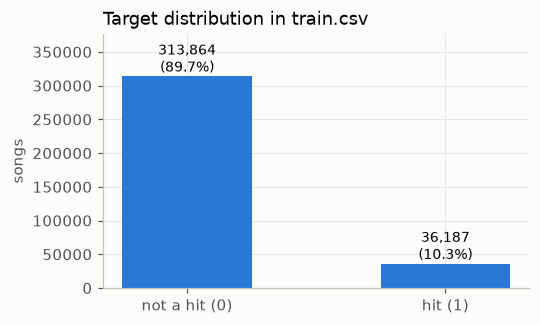

In [3]:
# count how many songs are hits (1) and non-hits (0)
counts = y.value_counts().sort_index()
print(pd.DataFrame({"count": counts, "share": (counts / len(y)).round(4)}))

# bar chart of the two classes, with count and percentage on top of each bar
fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(["not a hit (0)", "hit (1)"], counts.values, color=BLUE, width=0.5)
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}\n({v/len(y):.1%})", ha="center", va="bottom", fontsize=9)
ax.set_ylabel("songs"); ax.set_ylim(0, counts.max() * 1.2)
ax.set_title("Target distribution in train.csv", loc="left")
plt.show()
## imbalanced but still lots of hits compared to how few songs are actually hits 

**Interpretation.** ~10 % hits vs. ~90 % non-hits: moderate imbalance.
A model that always predicts "no hit" reaches ~90 % accuracy, so accuracy is meaningless here.
Because the metric is **AUC** (rank-based and insensitive to the class ratio), we do **not** resample (SMOTE/undersampling).
We will only use **stratified** splits so that every fold contains ~10 % hits.

## 2. Missing data

### 2a. Explicit missing values (NaN)

In [4]:
# number and percentage of empty cells per column, in train and test
miss = pd.DataFrame({
    "train_n":  train.isna().sum(),
    "train_%":  (train.isna().mean() * 100).round(2),
    "test_%":   (test.isna().mean() * 100).round(2).reindex(train.columns),
})
# only show columns that actually have missing values
miss[miss["train_n"] > 0]

,train_n,train_%,test_%
track_name,4,0.00,0.00
album_name,1,0.00,0.00
record_label,38,0.01,0.02
artist_genres,162592,46.45,46.55


### 2b. Hidden missing values
Some columns contain values that are physically implausible and most likely encode "unknown":
a tempo of 0 BPM, a time signature of 0 or 1, songs shorter than 30 s, 0 followers, loudness below −40 dB.

In [5]:
# a time signature of 0 or 1 beats per bar does not exist in real music
print("time_signature values:", sorted(train["time_signature"].unique()))

# min/max reveal impossible values, e.g. a duration or tempo of 0
print(train[["duration_sec", "audio_tempo", "audio_loudness", "artist_followers"]].describe().round(2))

time_signature values: [np.int64(0), np.int64(1), np.int64(3), np.int64(4), np.int64(5)]
       duration_sec  audio_tempo  audio_loudness  artist_followers
count     350051.00    350051.00       350051.00      3.500510e+05
mean         216.42       118.74          -11.16      2.474891e+06
std          118.80        30.40            6.47      9.733959e+06
min            0.00         0.00          -60.00      0.000000e+00
25%          161.00        95.03          -13.92      3.320000e+02
50%          205.68       119.84           -9.46      6.418000e+03
75%          252.04       137.89           -6.65      5.547040e+05
max         5407.67       249.43            2.87      1.159989e+08


## 3. Is missingness informative?
For each "missing" condition we compare the hit rate of the affected songs with the rest.

In [6]:
# each condition is a True/False mask marking the 'missing' or implausible rows
conditions = {
    "artist_genres missing":   train["artist_genres"].isna(),
    "artist_followers == 0":   train["artist_followers"] == 0,
    "duration < 30 s":         train["duration_sec"] < 30,
    "time_signature in {0,1}": train["time_signature"].isin([0, 1]),
    "audio_tempo == 0":        train["audio_tempo"] == 0,
    "loudness < -40 dB":       train["audio_loudness"] < -40,
}

# hit rate = mean of the 0/1 target, computed separately for affected rows (y[m]) and the rest (y[~m])
miss_info = pd.DataFrame({
    "n_rows":            {k: m.sum() for k, m in conditions.items()},
    "hit_rate_missing":  {k: y[m].mean() for k, m in conditions.items()},
    "hit_rate_rest":     {k: y[~m].mean() for k, m in conditions.items()},
}).round(3)
miss_info

,n_rows,hit_rate_missing,hit_rate_rest
artist_genres missing,162592,0.028,0.169
artist_followers == 0,2468,0.001,0.104
duration < 30 s,1683,0.000,0.104
"time_signature in {0,1}",5329,0.059,0.104
audio_tempo == 0,576,0.042,0.103
loudness < -40 dB,882,0.043,0.104


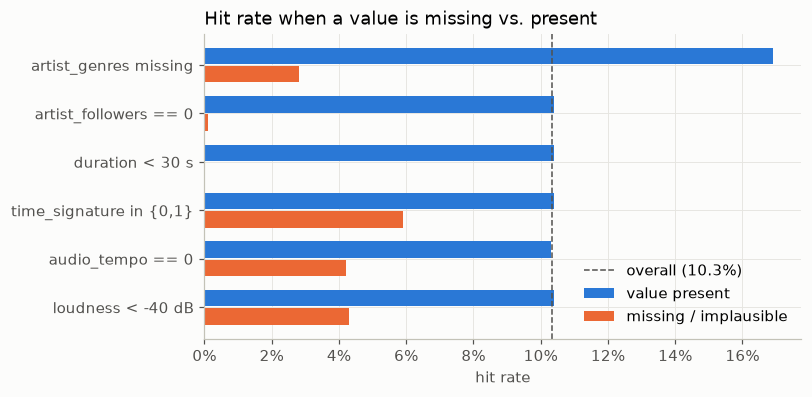

In [7]:
# grouped horizontal bars: blue = value present, orange = value missing / implausible
fig, ax = plt.subplots(figsize=(7, 3.6))
pos = np.arange(len(miss_info))
h = 0.38  # height of one bar
ax.barh(pos - h/2, miss_info["hit_rate_rest"], height=h - 0.04, color=BLUE, label="value present")
ax.barh(pos + h/2, miss_info["hit_rate_missing"], height=h - 0.04, color=ORANGE, label="missing / implausible")

# dashed line = hit rate of the whole dataset, for reference
ax.axvline(y.mean(), color=GREY, lw=1, ls="--", label=f"overall ({y.mean():.1%})")

ax.set_yticks(pos, miss_info.index); ax.invert_yaxis()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("hit rate"); ax.legend(frameon=False, loc="lower right")
ax.set_title("Hit rate when a value is missing vs. present", loc="left")
plt.show()

**Interpretation.** The data is **not missing at random**:
- A missing genre (46 % of rows, same share in test) means a hit rate of ~3 % instead of ~17 %. Missing genres mark obscure artists.
- Songs < 30 s or artists with 0 followers are practically never hits.

➡ Consequence for preprocessing: whatever imputation we use, we **keep a missing-indicator feature**.
Filling with the mean/mode alone would destroy one of the strongest signals in the data.

## 4. Other structure relevant for modelling

In [8]:
# release_date looks like 'YYYY-MM-DD' -> the first 4 characters are the year
year = train["release_date"].str[:4].astype(int)
print("release years:", year.min(), "-", year.max())

# hit rate per decade (1956 -> 1950, 1984 -> 1980, ...)
print("\nhit rate by decade:")
print(y.groupby((year // 10) * 10).agg(["mean", "size"]).round(3).T)

# hit rate per album type (album / single / compilation)
print("\nhit rate by album_type:")
print(y.groupby(train["album_type"]).agg(["mean", "size"]).round(3))

release years: 1956 - 2023

hit rate by decade:
release_date    1950     1960      1970      1980       1990       2000        2010        2020
mean            0.15     0.16     0.171     0.171      0.146      0.108       0.094       0.098
size          935.00  3342.00  5134.000  6154.000  17461.000  47166.000  138861.000  130998.000

hit rate by album_type:
              mean    size
album_type                
album        0.102  245226
compilation  0.116   35430
single       0.101   69395


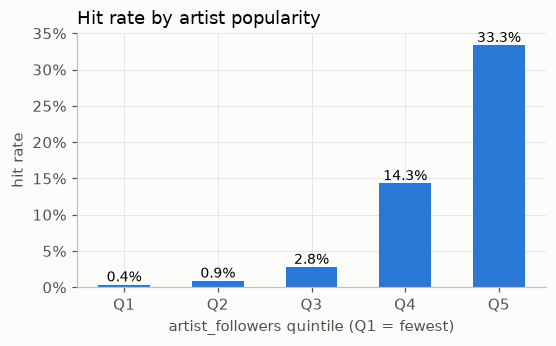

In [9]:
# split artists into 5 equally sized groups by follower count (Q1 = fewest, Q5 = most)
# rank() first, because many artists share the same follower count and qcut needs unique edges
q = pd.qcut(train["artist_followers"].rank(method="first"), 5, labels=[f"Q{i}" for i in range(1, 6)])
rate_q = y.groupby(q, observed=True).mean()

# bar chart of the hit rate per popularity group
fig, ax = plt.subplots(figsize=(5.5, 3))
ax.bar(rate_q.index.astype(str), rate_q.values, color=BLUE, width=0.55)
for i, v in enumerate(rate_q.values):
    ax.text(i, v, f"{v:.1%}", ha="center", va="bottom", fontsize=9)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("artist_followers quintile (Q1 = fewest)"); ax.set_ylabel("hit rate")
ax.set_title("Hit rate by artist popularity", loc="left")
plt.show()

# unspuprisingly pretty high hit rate with popular artists 

In [10]:
# how many test songs have an artist / label / album that already appears in train?
for col in ["artist_name", "record_label", "album_name"]:
    seen = test[col].isin(set(train[col]))
    print(f"{col:13s} unique in train: {train[col].nunique():6d} | test rows with value seen in train: {seen.mean():.1%}")

# per artist: hit rate and number of songs
art = train.groupby("artist_name")["music_hit"].agg(["mean", "size"])
big = art[art["size"] >= 20]  # only artists with enough songs to judge
print(f"\nartists with >= 20 songs whose hit rate is exactly 0 or 1: {big['mean'].isin([0, 1]).mean():.1%}")

# the same song title by the same artist appearing more than once (re-releases, compilations)
print("duplicate (track_name, artist_name) pairs in train:", train.duplicated(["track_name", "artist_name"]).sum())

artist_name   unique in train:  32596 | test rows with value seen in train: 95.7%
record_label  unique in train:  31558 | test rows with value seen in train: 96.0%


album_name    unique in train:  57310 | test rows with value seen in train: 92.7%

artists with >= 20 songs whose hit rate is exactly 0 or 1: 67.9%
duplicate (track_name, artist_name) pairs in train: 33471


**Interpretation.**
- Popularity dominates: from 0.4 % hits in the lowest follower quintile to 33 % in the highest. `artist_followers` is extremely skewed (0 – 116 M) → log transform for linear models.
- 96 % of test artists also appear in train, and most artists are "all hit" or "never hit" → target encoding of `artist_name` / `record_label` will be very strong, **but must be computed out-of-fold** to avoid leakage.
- Many re-released songs (duplicate track/artist pairs) → validation scores can be optimistic if copies end up on both sides of a split. But the copies are also useful: see *Re-released songs* below.

### Re-released songs
The same song often appears several times: as a single, on an album, as a remaster, on a compilation.
Such copies share the artist and (almost) the title, e.g. *"Yesterday"* and *"Yesterday - Remastered 2009"*.
We build a **song key** = artist + cleaned title (lowercase, without text in brackets or after `" - "`,
see `add_song_key` in `features.py`) and ask: does knowing that *another copy* was a hit tell us something?

test songs with a copy in train (raw title):     16.1%
test songs with a copy in train (cleaned title): 27.0%


                       mean    size
no other copy         0.077  254406
no copy is a hit      0.076   68658
some copies are hits  0.347   17422
all copies are hits   0.551    9565


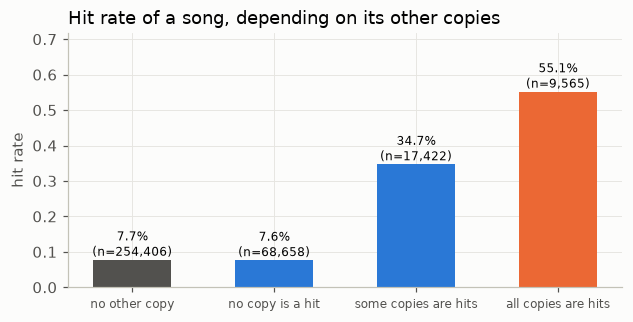

In [11]:
from features import add_song_key

# song key = artist + cleaned title, so re-releases of one song share the same key
train_key = add_song_key(train)["artist_title"]
test_key = add_song_key(test)["artist_title"]

# for comparison: the raw title, only lowercased (misses "- Remastered 2009" etc.)
def raw_key(df):
    return df["artist_name"].astype(str) + " || " + df["track_name"].fillna("").str.lower().str.strip()

print(f"test songs with a copy in train (raw title):     {raw_key(test).isin(set(raw_key(train))).mean():.1%}")
print(f"test songs with a copy in train (cleaned title): {test_key.isin(set(train_key)).mean():.1%}")

# hit rate of the OTHER copies of the same song (the song itself is left out of its own value)
n_copies = y.groupby(train_key).transform("size")
n_hits = y.groupby(train_key).transform("sum")
has_copy = n_copies > 1
other_rate = ((n_hits - y) / (n_copies - 1))[has_copy]

# group the songs: no copy at all / copies but none a hit / some copies hits / all copies hits
group = pd.Series("no other copy", index=train.index)
group[has_copy] = pd.cut(other_rate, [-0.01, 0, 0.999, 1],
                         labels=["no copy is a hit", "some copies are hits", "all copies are hits"]).astype(str)
order = ["no other copy", "no copy is a hit", "some copies are hits", "all copies are hits"]
rate = y.groupby(group).agg(["mean", "size"]).loc[order]
print(rate.round(3))

# bar chart: hit rate of a song depending on its other copies
fig, ax = plt.subplots(figsize=(6.5, 3))
colors = [GREY, BLUE, BLUE, ORANGE]
ax.bar(range(len(order)), rate["mean"], color=colors, width=0.55)
for i, (v, n) in enumerate(zip(rate["mean"], rate["size"])):
    ax.text(i, v, f"{v:.1%}\n(n={n:,})", ha="center", va="bottom", fontsize=8)
ax.set_xticks(range(len(order)), order, fontsize=8)
ax.set_ylabel("hit rate"); ax.set_ylim(0, rate["mean"].max() * 1.3)
ax.set_title("Hit rate of a song, depending on its other copies", loc="left")
plt.show()


**Interpretation.**
- About **27 %** of songs (train and test) have another copy in train. Cleaning the title matters: the raw title only finds 16 %.
- The other copies are a strong hint: if none of them is a hit, the song is a hit only **8 %** of the time,
  if some are hits **35 %**, if all are hits **55 %**.
- It is not a perfect copy of the label (a remaster or live version is not always a hit like the original),
  so it is a *feature*, not a rule.

➡ Consequence: the song key `artist_title` gets a count feature and an **out-of-fold target encoding**, just like artist, label and album.
It overlaps partly with the artist and album encodings, so the gain is small but consistent:
gradient boosting improves by **+0.0008 AUC on each of the 5 CV folds**.

## 5. Single-feature AUC – the baseline to beat
AUC of each numeric feature used directly as a score.
An AUC below 0.5 just means the feature works "the other way round" (e.g. *more* instrumental = *fewer* hits),
so we report `max(AUC, 1 − AUC)`.

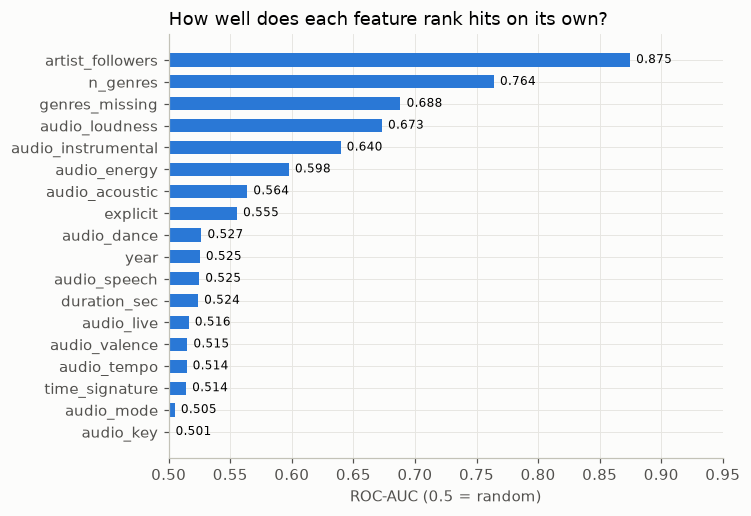

In [12]:
# a few simple derived features, to test them alongside the raw columns
feat = train.copy()
feat["year"] = year
feat["genres_missing"] = feat["artist_genres"].isna().astype(int)  # 1 if no genre is known
# genres are a '|'-separated list, e.g. 'pop|dance pop' -> split and count (0 if missing)
feat["n_genres"] = feat["artist_genres"].str.split("|").str.len().fillna(0)
feat["explicit"] = feat["explicit_lyrics"].astype(int)  # True/False -> 1/0

# AUC of every numeric column when used directly as the prediction score
num_cols = [c for c in feat.select_dtypes("number").columns if c not in ("id", "music_hit")]
auc = pd.Series({c: roc_auc_score(y, feat[c]) for c in num_cols})
auc = np.maximum(auc, 1 - auc).sort_values()  # flip features that work 'the other way round'

# horizontal bars starting at 0.5 (= random guessing)
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.barh(auc.index, auc.values - 0.5, left=0.5, color=BLUE, height=0.6)
for i, v in enumerate(auc.values):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=8)
ax.set_xlim(0.5, 0.95); ax.set_xlabel("ROC-AUC (0.5 = random)")
ax.set_title("How well does each feature rank hits on its own?", loc="left")
plt.show()

**Interpretation.** `artist_followers` alone reaches **AUC ≈ 0.875** – every model has to beat this.
The number of genres an artist has (`n_genres`) is the second strongest signal: well-known artists get more genre tags.
Audio features are individually weak (mostly < 0.6): whether a song becomes a hit depends much more on *who* made it than on *how it sounds*.
They may still help in interaction with other features, which tree-based models can exploit.

## Summary → decisions
| Finding | Decision |
|---|---|
| 10 % hits, metric = AUC | no resampling, stratified splits |
| Missingness strongly predictive | keep missing-indicator features |
| Hidden missing values (0 tempo, time_sig 0/1, …) | convert to NaN before imputation |
| Skewed followers / duration | log transform for linear / distance-based models |
| Artists repeat between train and test | out-of-fold target encoding |
| Duplicate songs | check that the validation split mirrors the train/test overlap (notebook 02) |
| Re-released songs: other copies' hit rate is predictive | song key (artist + cleaned title) with out-of-fold target encoding |